<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">I</span>
&nbsp;—&nbsp;
Acquisition des ressources
</h2>

<h3 style="
    color: #4F7F52;
    border-bottom: 1px solid #4F7F52;
    padding-bottom: 3px;
    font-size: 1.25em;
">
<span style="
    font-weight: bold;
    font-style: italic;
">1.</span>
&nbsp;
Téléchargement des bulletins mensuels de l'année 2025 de l'OVSM
</h3>

Cette cellule permet de télécharger les douze bulletins mensuels de l'année
2025 publiés par l'OVSM.

La fonction `url_management()` construit, pour chaque mois étudié, les URL
candidates correspondant aux deux périodes possibles de publication du
bulletin.

<h3 style="
    color: #4F7F52;
    border-bottom: 1px solid #4F7F52;
    padding-bottom: 3px;
    font-size: 1.25em;
">
<span style="
    font-weight: bold;
    font-style: italic;
">2.</span>
&nbsp;
Contrôles du programme
</h3>

Le programme vérifie ensuite :

1. si le bulletin est déjà présent dans le dossier local `corpus/pdf` ;
2. si le fichier présent localement est bien un document PDF ;
3. si l'une des URL candidates permet effectivement d'obtenir le bulletin ;
4. si la ressource téléchargée correspond bien à un fichier PDF.

<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">

<strong>RÈGLE DE COURTOISIE</strong><br>
Un délai d'une seconde est respecté entre deux requêtes successives afin de
limiter la fréquence des sollicitations adressées au serveur de l'IPGP.

<strong>GESTION DES MÉTADONNÉES</strong><br>
Pour chaque bulletin sont enregistrés : le mois, l'URL d'origine, la date et l'heure de récupération, l'empreinte SHA-256 et la taille du fichier.
Ces informations sont sauvegardées dans
<code>data/metadonnees.json</code>.

</div>

In [1]:
# Téléchargements
import time
import requests, hashlib, datetime, pathlib
import json

HEADERS = {"User-Agent": "Mozilla/5.0 (projet universitaire Paris 8 - corpus OVSM)"}

MOIS = ["2025_01", "2025_02", "2025_03", "2025_04", "2025_05", "2025_06",
        "2025_07", "2025_08", "2025_09", "2025_10", "2025_11", "2025_12"]
# NB : le dossier AAAA/MM de mise en ligne est décalé d'un à deux mois
# par rapport au mois couvert ; le script teste les deux candidats.

DEST = pathlib.Path("corpus/pdf")
DEST.mkdir(parents=True, exist_ok=True)

def url_management(mois):
    an, m = mois.split("_")
    for delta in (1, 2): # décalage de publication
        m2 = int(m) + delta
        an2 = int(an) + (m2 - 1) // 12
        m2 = (m2 - 1) % 12 + 1
        yield (f"https://www.ipgp.fr/wp-content/uploads/"
               f"{an2}/{m2:02d}/OVSM_{mois}_fra.pdf")
        
# liste remplie grâce à la boucle for
metadonnees = []
# Pour chaque mois d'une période :
for mois in MOIS:

    # Déclaration du chemin vers dossier de sauvegarde
    chemin = DEST / f"OVSM_{mois}.pdf"

    if chemin.exists():

        contenu = chemin.read_bytes()

        # On vérifie qu'il s'agit réellement d'un fichier PDF.
        if contenu[:4] == b"%PDF":

            print(f"[DÉJÀ PRÉSENT] {mois}")

            # Le bulletin présent localement doit aussi être comptabilisé
            # dans les métadonnées.
            metadonnees.append({
                "mois": mois,
                "url": None,
                "timestamp": datetime.datetime.now().isoformat(),
                "checksum": hashlib.sha256(contenu).hexdigest(),
                "taille": len(contenu),
                "origine": "cache_local"
            })

            continue

    # Si le bulletin n'est pas présent localement,
    # on cherche son URL de publication.
    for url in url_management(mois):
        try:
            
            # Téléchargement bulletin de la période
            #r = requests.get(url, timeout=30) 
            r = requests.get(url, timeout=30, headers=HEADERS)
            
        except requests.RequestException as e:
            print(f"[Erreur connexion réseau]{url} : {e}")
            continue
            
        if r.status_code == 200 and r.content[:4] == b"%PDF":
            
            # Enregistre dans le dossier DEST
            chemin = DEST / f"OVSM_{mois}.pdf"
            chemin.write_bytes(r.content)
            
            # Infos récupérées
            metadonnees.append({
                "mois": mois, "url": url,
                "timestamp": datetime.datetime.now().isoformat(),
                "checksum": hashlib.sha256(r.content).hexdigest(),
                "taille": len(r.content)
            })
            break
    else:
        print(f"[MANQUANT] {mois} : aucun candidat trouvé")
    time.sleep(1)
# Persistance des métadonnées : la liste ne survit pas au redémarrage
# du noyau, on la sauvegarde donc sur disque au format JSON.
pathlib.Path("data").mkdir(exist_ok=True)
pathlib.Path("data/metadonnees.json").write_text(
    json.dumps(metadonnees, ensure_ascii=False, indent=1), encoding="utf-8")

print(f"{len(metadonnees)} bulletins récupérés / {len(MOIS)}")

12 bulletins récupérés / 12


<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">II</span>
&nbsp;—&nbsp;
Conversion et nettoyage des ressources
</h2>

<h3 style="
    color: #4F7F52;
    border-bottom: 1px solid #4F7F52;
    padding-bottom: 3px;
    font-size: 1.25em;
">
<span style="
    font-weight: bold;
    font-style: italic;
">1.</span>
&nbsp;
Extraction du texte et des tableaux
</h3>

Cette cellule permet de convertir les douze bulletins mensuels, initialement disponibles au format PDF, en ressources textuelles exploitables par la suite du programme.

Une première boucle `for` parcourt l'ensemble des fichiers PDF présents dans le dossier `corpus/pdf`. La méthode `glob("*.pdf")` permet de sélectionner uniquement les fichiers possédant l'extension `.pdf`, tandis que la fonction `sorted()` les ordonne avant leur traitement.

Pour chaque bulletin, deux listes vides sont créées :

- `texte`, destinée à recevoir le contenu textuel des différentes pages ;
- `tableaux`, destinée à recevoir les tableaux détectés dans le document.

Le fichier PDF est ensuite ouvert à l'aide de la méthode `open()` de la
bibliothèque `pdfplumber`. Une seconde boucle `for` parcourt chacune de ses
pages. La méthode `extract_text()` extrait le contenu textuel de la page et
l'ajoute à la liste `texte`. En parallèle, la méthode `extract_tables()`
recherche les tableaux présents sur la page et ajoute ceux qui sont détectés à la liste `tableaux`.

<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">

<strong>ORGANISATION DES DOSSIERS</strong><br>
Une fois toutes les pages traitées, l'attribut <code>stem</code> permet de
récupérer le nom du fichier PDF sans son extension. Ce nom est réutilisé
pour créer les deux fichiers associés au bulletin :
<ul>
    <li>
        une version textuelle, enregistrée dans
        <code>corpus/txt_brut/OVSM_AAAA_MM.txt</code> ;
    </li>
    <li>
        une représentation des tableaux au format JSON, enregistrée dans
        <code>corpus/txt_brut/OVSM_AAAA_MM_tables.json</code>.
    </li>
</ul>
Nous conservons ainsi séparément le texte brut des bulletins et les tableaux
qui serviront ultérieurement à l'extraction des variables numériques.
</div>

In [2]:
# Conversion des documents PDF au format texte
import pdfplumber, pathlib, json

for pdf_path in sorted(pathlib.Path("corpus/pdf").glob("*.pdf")):
    texte, tableaux = [], []
    with pdfplumber.open(pdf_path) as pdf:
        for page in pdf.pages:
            texte.append(page.extract_text() or "")
            for t in page.extract_tables():
                tableaux.append(t)
    stem = pdf_path.stem
    pathlib.Path(f"corpus/txt_brut/{stem}.txt").write_text(
        "\n".join(texte), encoding="utf-8")
    pathlib.Path(f"corpus/txt_brut/{stem}_tables.json").write_text(
        json.dumps(tableaux, ensure_ascii=False, indent=1), encoding="utf-8")

<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">II</span>
&nbsp;—&nbsp;
Conversion et nettoyage des ressources
</h2>

<h3 style="
    color: #4F7F52;
    border-bottom: 1px solid #4F7F52;
    padding-bottom: 3px;
    font-size: 1.25em;
">
<span style="
    font-weight: bold;
    font-style: italic;
">2.</span>
&nbsp;
Nettoyage des ressources textuelles
</h3>

<p>
Cette cellule permet de nettoyer les versions textuelles des douze bulletins
mensuels obtenues lors de l'étape précédente. L'objectif est de supprimer
certains éléments qui ne sont pas utiles à l'analyse du contenu volcanologique
et qui pourraient introduire du bruit dans les traitements ultérieurs.
</p>

<p>
Les éléments considérés comme indésirables ont été repérés à partir de
l'analyse de la structure d'un bulletin pilote. Les expressions régulières
permettant de les identifier ont ensuite été construites à partir de la
syntaxe des expressions régulières, notamment documentée sur le site
<a href="https://www.regular-expressions.info">
regular-expressions.info
</a>.
</p>

<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">

<strong>IDENTIFICATION DES ÉLÉMENTS INDÉSIRABLES</strong>

<p style="margin-bottom: 5px;">
Les principaux motifs de bruit sont regroupés dans la liste
<code>MOTIFS_BRUIT</code>. Ils correspondent principalement à trois catégories.
</p>
<!--IL NE FAUT PAS LAISSER D'ESPACES ENTRE LES BLOCS LI SINON ÇA APPARAITRA EN BRUT PAS EN TEXTE-->
<ol style="
    margin-top: 4px;
    margin-bottom: 8px;
    padding-left: 25px;
">
    <li>
        <strong>En-têtes, pieds de page et éléments éditoriaux :</strong>
        nom de l'Observatoire, mention <code>OVSM-IPGP</code>,
        titre du bulletin, Institut de physique du globe, numéro ISSN,
        numéros de page et certaines légendes de figures.
    </li>
    <li>
        <strong>Artefacts issus de l'extraction PDF :</strong>
        formes dont les mots apparaissent collés après l'extraction réalisée
        par <code>pdfplumber</code>, certaines adresses et les noms des
        réseaux sociaux.
    </li>
    <li>
        <strong>Résidus typographiques :</strong>
        lignes constituées uniquement de chiffres isolés pouvant notamment
        provenir de la récupération séparée d'indices typographiques.
    </li>
</ol>

</div>

<p style="margin-top: 4px;">
La fonction <code>nettoyer()</code> prend en paramètre une chaîne de
caractères contenant le texte d'un bulletin et retourne une nouvelle chaîne
correspondant à sa version nettoyée.
Elle commence par appliquer <code>unicodedata.normalize("NFC", texte)</code> afin d'uniformiser la
représentation Unicode des caractères. Une boucle <code>for</code> parcourt ensuite l'ensemble des expressions
régulières contenues dans <code>MOTIFS_BRUIT</code>. Pour chaque motif,
la fonction <code>re.sub()</code> recherche les séquences correspondantes
dans le texte et les remplace par une chaîne vide.
</p>

<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">

<strong>TRAITEMENTS COMPLÉMENTAIRES</strong>

<p style="margin-bottom: 5px;">
Après la suppression des éléments indésirables, trois traitements
complémentaires sont appliqués :
</p>

<ul style="
    margin-top: 4px;
    margin-bottom: 8px;
    padding-left: 25px;
">
    <li>
        suppression des césures introduites en fin de ligne ;
    </li>
    <li>
        réduction des suites d'espaces ou de tabulations à un seul espace ;
    </li>
    <li>
        réduction des successions de plusieurs lignes vides.
    </li>
</ul>

</div>

<p style="margin-top: 4px;">
Enfin, la méthode <code>strip()</code> supprime les espaces et les retours
à la ligne résiduels situés au début et à la fin de la chaîne de caractères.
</p>

<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">

<strong>ORGANISATION DES FICHIERS</strong>

<p style="margin-bottom: 5px;">
Une dernière boucle <code>for</code> parcourt les fichiers
<code>.txt</code> présents dans le dossier
<code>corpus/txt_brut</code>. Pour chacun d'eux, la fonction
<code>nettoyer()</code> est appliquée puis le résultat est enregistré
dans le dossier <code>corpus/txt_propre</code>.
Le nom du fichier d'origine est conservé et les fichiers sont enregistrés
avec un encodage UTF-8.
</p>
</div>
<p style="margin-top: 4px;">
Cette étape concerne uniquement les ressources textuelles :
les fichiers de tableaux au format JSON obtenus lors de l'étape précédente
ne sont pas modifiés.
</p>




In [3]:
# Nettoyage des ressources
import re, pathlib, unicodedata

MOTIFS_BRUIT = [
    # Formes espacées des en-têtes/pieds de page
    r"(?im)^\s*Observatoire volcanologique et sismologique.*$",
    r"(?im)^\s*OVSM[- ]IPGP.*$",
    r"(?im)^\s*Bulletin mensuel.*$",
    r"(?im)^\s*Institut de physique du globe.*$",
    r"(?im)^\s*ISSN \d{4}-\d{4}\s*$",
    r"(?im)^\s*Page \d+\s*(/|sur)\s*\d+\s*$",
    r"(?im)^\s*Figure \d+\s*[:.].*$",
    # Variantes collées des en-têtes/pieds de page (bruit pdfplumber)
    r"(?im)^\s*Observatoirevolcanologique.*$",
    r"(?im)^\s*Institutdephysiqueduglobe.*$",
    r"(?im)^\s*Lieudit.*$",
    r"(?im)^\s*Routedel.*$",
    r"(?im)^\s*97250Saint-Pierre.*$",
    r"(?im)^\s*(Bluesky|Facebook|Youtube)\s*$",
    # Ligne résiduelle des indices typographiques (ex. « 2 2 » du CO2)
    r"(?m)^\s*\d(?:\s+\d)*\s*$",
]

def nettoyer(texte: str) -> str:
    texte = unicodedata.normalize("NFC", texte)   # uniformisation Unicode
    for motif in MOTIFS_BRUIT:
        texte = re.sub(motif, "", texte)
    texte = re.sub(r"-\n(?=\w)", "", texte)       # césures de fin de ligne
    texte = re.sub(r"[ \t]+", " ", texte)
    texte = re.sub(r"\n{3,}", "\n\n", texte)      # lignes vides multiples
    return texte.strip()

for brut in sorted(pathlib.Path("corpus/txt_brut").glob("*.txt")):
    propre = nettoyer(brut.read_text(encoding="utf-8"))
    pathlib.Path(f"corpus/txt_propre/{brut.name}").write_text(
        propre, encoding="utf-8")

<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">III</span>
&nbsp;—&nbsp;
Stockage des données dans SQLite
</h2>


<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">

<strong>OBJECTIF RECHERCHÉ AVEC LA BASE DE DONNÉES</strong>

<ul style="
    margin-top: 4px;
    margin-bottom: 8px;
    padding-left: 25px;
">
<li>
<strong>Système retenu :</strong>
SQLite, qui peut être utilisé directement en Python à l'aide du module
standard <code>sqlite3</code>.
</li>
<li>
<strong>Fichier de la base :</strong>
<code>data/corpus_pelee.db</code>.
</li>
<li>
<strong>Objectif principal :</strong>
centraliser dans une même structure persistante les métadonnées, les textes
et, ultérieurement, les variables mensuelles extraites des bulletins.
</li>
<li>
<strong>Réexécution du notebook :</strong>
les données enregistrées dans le fichier SQLite restent disponibles après
l'arrêt ou le redémarrage du noyau Jupyter. Les cellules suivantes peuvent
donc relire les données sans devoir reconstruire systématiquement le corpus.
</li>
</ul>

<p style="margin-top: 4px;">
À ce stade, la base ne constitue pas encore une représentation dite
« large » des données. La table <code>variable_mensuelle</code> est conçue
pour associer plusieurs variables à un même bulletin. La transformation vers
un tableau comportant un mois par ligne et une variable par colonne sera
réalisée ultérieurement lors du prétraitement.
</p>

</div>


<h3 style="
    color: #4F7F52;
    border-bottom: 1px solid #4F7F52;
    padding-bottom: 3px;
    font-size: 1.25em;
">
<span style="
    font-weight: bold;
    font-style: italic;
">1.</span>
&nbsp;
Étapes préalables à la création des tables
</h3>


<strong>Récupération des métadonnées</strong>

<p>
Les métadonnées enregistrées lors de l'acquisition des ressources sont
rechargées depuis le fichier <code>data/metadonnees.json</code>.
La méthode <code>read_text()</code> lit son contenu sous la forme d'une
chaîne de caractères, puis la fonction <code>json.loads()</code> interprète
cette chaîne JSON et reconstruit la structure Python précédemment enregistrée,
ici une liste de dictionnaires.
</p>

<p>
Cette persistance évite d'avoir à télécharger de nouveau les bulletins
uniquement pour reconstruire les métadonnées après un redémarrage du noyau.
</p>


<strong>Connexion à la base SQLite</strong>

<p>
L'instruction <code>sqlite3.connect("data/corpus_pelee.db")</code> ouvre
une connexion avec la base SQLite. Si le fichier n'existe pas encore,
SQLite le crée automatiquement.
</p>

<p>
L'objet de connexion est conservé dans la variable <code>con</code>.
Il sera utilisé pour transmettre au moteur SQLite les instructions de
création des tables, d'insertion des données puis, dans les étapes suivantes,
de lecture des informations enregistrées.
</p>


<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">

<strong>CAS DES BULLETINS DÉJÀ PRÉSENTS LOCALEMENT</strong>

<p style="margin-bottom: 4px;">
Lors de l'acquisition, lorsqu'un bulletin était déjà présent dans
<code>corpus/pdf</code>, la valeur de son URL était enregistrée sous la forme
<code>null</code> dans le fichier JSON. La colonne
<code>url_source</code> de la table <code>bulletin</code> doit donc accepter
une valeur nulle.
</p>

<p style="margin-top: 4px;">
Dans ce cas, le fichier, son mois et son empreinte SHA-256 sont connus,
mais l'URL exacte utilisée lors de son téléchargement initial ne peut pas
être reconstruite avec certitude.
</p>

</div>


<h3 style="
    color: #4F7F52;
    border-bottom: 1px solid #4F7F52;
    padding-bottom: 3px;
    font-size: 1.25em;
">
<span style="
    font-weight: bold;
    font-style: italic;
">2.</span>
&nbsp;
Création et organisation des tables
</h3>


<p>
Le projet manipule deux catégories d'informations de nature différente.
Deux tables sont donc créées dans la base.
</p>

<ol style="
    margin-top: 4px;
    margin-bottom: 8px;
    padding-left: 25px;
">
<li>
<strong>La table <code>bulletin</code></strong> regroupe les informations
directement attachées à chaque bulletin de l'OVSM : mois, URL source,
date de récupération, empreinte SHA-256 ainsi que les deux représentations
textuelles obtenues précédemment. Les colonnes <code>texte_brut</code> et
<code>texte_propre</code> permettent ainsi de conserver simultanément le texte
avant et après nettoyage.
</li>
<li>
<strong>La table <code>variable_mensuelle</code></strong> est destinée à
recevoir les variables extraites pour la fouille de données. La colonne
<code>type</code> distingue les variables <code>quantitative</code> et
<code>qualitative</code>. La clé primaire composée
<code>(bulletin_id, nom)</code> garantit qu'une même variable ne puisse être
enregistrée qu'une seule fois pour un bulletin donné.
</li>
</ol>

<p>
Les deux tables sont créées avec la méthode <code>executescript()</code>,
qui permet ici d'envoyer plusieurs instructions SQL successives au moteur
SQLite.
</p>

<p>
La clause <code>CREATE TABLE IF NOT EXISTS</code> demande de créer une table
uniquement lorsqu'elle n'existe pas déjà. Elle permet ainsi de réexécuter
cette cellule sans provoquer d'erreur liée à l'existence préalable des tables.
</p>

<p>
Dans la table <code>bulletin</code>, la contrainte
<code>UNIQUE</code> appliquée à <code>mois</code> empêche l'enregistrement
de plusieurs lignes pour une même période, tandis que
<code>NOT NULL</code> impose qu'un mois soit obligatoirement renseigné.
</p>


<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">

<strong>RELATION ENTRE LES DEUX TABLES</strong>

<p style="margin-bottom: 4px;">
Un bulletin correspond à une seule ligne de la table
<code>bulletin</code>.
</p>

<p style="margin-top: 4px;">
En revanche, ce bulletin pourra être associé à plusieurs lignes de la table
<code>variable_mensuelle</code>, chacune représentant une variable particulière.
La colonne <code>bulletin_id</code> assure cette liaison avec l'identifiant du
bulletin concerné.
</p>

</div>


<h3 style="
    color: #4F7F52;
    border-bottom: 1px solid #4F7F52;
    padding-bottom: 3px;
    font-size: 1.25em;
">
<span style="
    font-weight: bold;
    font-style: italic;
">3.</span>
&nbsp;
Insertion des textes dans la base
</h3>


<p>
L'insertion des données commence par la boucle :
</p>

<pre><code>for meta in metadonnees:</code></pre>

<p>
Cette boucle parcourt les dictionnaires contenus dans la liste
<code>metadonnees</code> reconstruite depuis le fichier JSON.
À chaque itération, la variable <code>meta</code> contient les informations
relatives à un bulletin.
</p>

<p>
L'instruction :
</p>

<pre><code>stem = f"OVSM_{meta['mois']}"</code></pre>

<p>
reconstruit le nom de base des fichiers à partir du mois du bulletin.
Par exemple, lorsque <code>meta["mois"]</code> vaut
<code>"2025_01"</code>, la variable <code>stem</code> prend la valeur
<code>"OVSM_2025_01"</code>.
</p>

<p>
Le programme peut alors retrouver automatiquement les deux fichiers
correspondants dans les dossiers <code>corpus/txt_brut</code> et
<code>corpus/txt_propre</code>.
</p>

<p>
La méthode :
</p>

<pre><code>con.execute(...)</code></pre>

<p>
transmet ensuite une instruction SQL au moteur SQLite.
Dans l'instruction :
</p>

<pre><code>VALUES (?,?,?,?,?,?)</code></pre>

<p>
les six points d'interrogation représentent des paramètres SQL.
Les valeurs correspondantes sont fournies séparément dans un tuple Python.
Cette écriture évite de construire directement la requête SQL par
concaténation de chaînes de caractères.
</p>

<p style="margin-bottom: 4px;">
Le tuple fournit successivement :
</p>

<ol style="
    margin-top: 4px;
    margin-bottom: 8px;
    padding-left: 25px;
">
<li>le mois du bulletin ;</li>
<li>l'URL source, éventuellement nulle ;</li>
<li>le timestamp de récupération ;</li>
<li>l'empreinte SHA-256 du PDF ;</li>
<li>le texte brut ;</li>
<li>le texte nettoyé.</li>
</ol>

<p>
Les deux appels à <code>read_text()</code> récupèrent directement le contenu
des fichiers créés lors des étapes précédentes. La base ne conserve donc pas
seulement leur emplacement sur le disque : elle enregistre également leur
contenu textuel.
</p>


<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">

<strong>RÉEXÉCUTION DE L'INSERTION</strong>

<p>
L'instruction <code>INSERT OR REPLACE</code> permet ici de remplacer
l'enregistrement correspondant lorsqu'un conflit intervient sur la contrainte
d'unicité du mois. Ce choix facilite la réexécution de la cellule pendant la
phase de constitution du corpus.
</p>

</div>


<p>
Enfin, l'instruction :
</p>

<pre><code>con.commit()</code></pre>

<p>
valide la transaction. Les modifications effectuées sont alors enregistrées
de manière persistante dans le fichier
<code>data/corpus_pelee.db</code>.
</p>

In [4]:
# Stockage des données
import sqlite3, pathlib, json

# Rechargement des métadonnées persistées à l'aspiration : la cellule
# devient ré-exécutable indépendamment, sans retéléchargement.
metadonnees = json.loads(
    pathlib.Path("data/metadonnees.json").read_text(encoding="utf-8")
)

con = sqlite3.connect(
    "data/corpus_pelee.db",
    timeout=30
)

# CORRECTION : activation des clés étrangères pour cette connexion
con.execute("PRAGMA foreign_keys = ON")

con.executescript("""
CREATE TABLE IF NOT EXISTS bulletin (
    id          INTEGER PRIMARY KEY,
    mois        TEXT UNIQUE NOT NULL,   -- ex. '2025_01'
    url_source  TEXT,
    timestamp   TEXT NOT NULL,          -- moment de la récolte
    checksum    TEXT NOT NULL,          -- SHA-256 du PDF
    codage      TEXT DEFAULT 'utf-8',
    format_src  TEXT DEFAULT 'pdf',
    texte_brut  TEXT,
    texte_propre TEXT
);
CREATE TABLE IF NOT EXISTS variable_mensuelle (
    bulletin_id INTEGER REFERENCES bulletin(id),
    nom         TEXT NOT NULL,          -- ex. 'nb_vt_superficiels'
    valeur      TEXT,                   -- stockée en texte, typée à la lecture
    type        TEXT CHECK(type IN ('quantitative','qualitative')),
    PRIMARY KEY (bulletin_id, nom)
);
""")
for meta in metadonnees: # liste construite à l'aspiration
    stem = f"OVSM_{meta['mois']}"
    con.execute(
        """
        INSERT INTO bulletin (
            mois,
            url_source,
            timestamp,
            checksum,
            texte_brut,
            texte_propre
        )
        VALUES (?, ?, ?, ?, ?, ?)
        ON CONFLICT(mois) DO UPDATE SET
            url_source = excluded.url_source,
            timestamp = excluded.timestamp,
            checksum = excluded.checksum,
            texte_brut = excluded.texte_brut,
            texte_propre = excluded.texte_propre
        """,
        (
            meta["mois"],
            meta["url"],
            meta["timestamp"],
            meta["checksum"],
            pathlib.Path(
                f"corpus/txt_brut/{stem}.txt"
            ).read_text(encoding="utf-8"),
            pathlib.Path(
                f"corpus/txt_propre/{stem}.txt"
            ).read_text(encoding="utf-8")
        )
    )
# CORRECTION : nettoyage des anciennes lignes déjà devenues orphelines
con.execute(
    """
    DELETE FROM variable_mensuelle
    WHERE bulletin_id NOT IN (
        SELECT id
        FROM bulletin
    )
    """
)

con.commit()


<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">III</span>
&nbsp;—&nbsp;
Stockage et constitution du corpus
</h2>

<h3 style="
    color: #4F7F52;
    border-bottom: 1px solid #4F7F52;
    padding-bottom: 3px;
    font-size: 1.25em;
">
<span style="
    font-weight: bold;
    font-style: italic;
">2.</span>
&nbsp;
Caractéristiques du corpus
</h3>

<p>
À l'issue des étapes précédentes, la constitution technique du corpus est
achevée. Celui-ci comprend les douze bulletins mensuels correspondant aux
douze mois de l'année 2025.
</p>

<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">

<strong>REPRÉSENTATIONS CONSERVÉES POUR CHAQUE BULLETIN</strong>

<p style="margin-bottom: 4px;">
Chaque document est disponible sous plusieurs représentations complémentaires :
</p>

<ul style="
    margin-top: 4px;
    margin-bottom: 8px;
    padding-left: 25px;
">
<li>le fichier PDF original ;</li>
<li>le texte brut extrait du PDF ;</li>
<li>le texte nettoyé ;</li>
<li>les tableaux extraits et enregistrés au format JSON ;</li>
<li>
les métadonnées, le texte brut et le texte nettoyé enregistrés dans
la base SQLite <code>data/corpus_pelee.db</code>.
</li>
</ul>

</div>

<p>
Cette cellule permet maintenant de produire une synthèse quantitative du
corpus directement à partir des données effectivement enregistrées dans la
base, afin d'éviter de recourir à des estimations manuelles.
</p>

<p>
La connexion à <code>data/corpus_pelee.db</code> permet d'abord de récupérer
la colonne <code>texte_propre</code> de tous les bulletins, ordonnés selon
leur mois. Les textes obtenus sont placés dans la liste <code>docs</code>,
puis réunis dans une seule chaîne de caractères nommée <code>corpus</code>.
</p>

<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">

<strong>CARACTÉRISTIQUES CALCULÉES</strong>

<p style="margin-bottom: 4px;">
Le programme calcule cinq indicateurs décrivant le corpus :
</p>

<ol style="
    margin-top: 4px;
    margin-bottom: 8px;
    padding-left: 25px;
">
<li>
<strong>Nombre de documents :</strong>
la fonction <code>len(docs)</code> détermine le nombre de textes récupérés
dans la table <code>bulletin</code>.
</li>
<li>
<strong>Nombre de caractères :</strong>
la longueur de chacun des textes est calculée avec <code>len()</code>, puis
les résultats sont additionnés afin d'obtenir la taille textuelle totale
du corpus.
</li>
<li>
<strong>Nombre de tokens :</strong>
l'expression régulière
<code>[a-zàâçéèêëîïôùûü'-]{3,}</code> sélectionne, après passage du corpus
en minuscules, les séquences d'au moins trois caractères correspondant
au motif retenu.
</li>
<li>
<strong>Nombre de formes distinctes :</strong>
la conversion de la liste des tokens en ensemble avec <code>set(tokens)</code>
élimine les répétitions. La fonction <code>len()</code> permet ensuite de
compter les formes différentes présentes dans le corpus.
</li>
<li>
<strong>Taille de la base SQLite :</strong>
la propriété <code>st_size</code> fournit la taille physique du fichier
<code>data/corpus_pelee.db</code>, exprimée en octets.
</li>
</ol>

</div>

<p>
Les résultats obtenus fournissent ainsi une description quantitative du corpus
réellement constitué : nombre de documents, volume textuel, nombre de tokens,
diversité des formes lexicales et taille du fichier de base de données.
</p>

In [5]:
# CARACTÉRISTIQUES DU CORPUS
import pathlib, re, sqlite3
	
con = sqlite3.connect(
	"data/corpus_pelee.db"
)
	
docs = [
	texte
	for (texte,) in con.execute(
    	"SELECT texte_propre "
    	"FROM bulletin "
    	"ORDER BY mois"
	)
]
	
corpus = "\n".join(docs)

tokens = re.findall(
    r"[a-zàâçéèêëîïôùûü'-]{3,}",
    corpus.lower()
)

nb_documents = len(docs)
nb_caracteres = sum(
    len(texte)
    for texte in docs
)
nb_tokens = len(tokens)
nb_formes = len(set(tokens))

taille_base = pathlib.Path(
    "data/corpus_pelee.db"
).stat().st_size

print(
    "Documents :", nb_documents
)
print(
    "Caractères :", nb_caracteres
)
print(
    "Tokens :", nb_tokens
)
print(
    "Formes distinctes :", nb_formes
)
print(
    "Taille de la base :", taille_base,
    "octets"
)



Documents : 12
Caractères : 504340
Tokens : 32946
Formes distinctes : 4032
Taille de la base : 1265664 octets


<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">IV</span>
&nbsp;—&nbsp;
Passage de la fouille de données à l'apprentissage automatique
</h2>


Le notebook précédent a permis de constituer et de nettoyer le corpus des bulletins
mensuels de l'OVSM, d'enregistrer les textes dans SQLite, de construire un
mini-lexique et d'extraire plusieurs variables mensuelles.

La présente partie prolonge ce travail en ajoutant une tâche d'**apprentissage
supervisé**. L'objectif est de construire un perceptron multicouche capable
d'associer automatiquement un passage textuel à l'une des trois classes suivantes :

- `sismicite_volcanique` ;
- `deformation_sol` ;
- `geochimie`.

Le cours d'**Intelligence artificielle et apprentissage** rappelle que
le perceptron multicouche est un réseau composé d'une couche d'entrée, d'une ou plusieurs couches cachées et d'une couche de sortie. Il insiste également sur l'intérêt d'une fonction d'activation non linéaire dans les couches cachées et sur l'utilisation d'une fonction de perte adaptée à la tâche de classification.

Dans notre cas, chaque observation représente passage
de texte extrait d'un bulletin. Il faut donc transformer le texte en valeurs numériques avant de pouvoir le transmettre aux couches `Dense`.

<div style="
    border-left: 4px solid #4F7F52;
    padding-left: 12px;
    margin-top: 15px;
">
<strong>PRINCIPE MÉTHODOLOGIQUE</strong><br>
Les titres de rubriques des bulletins sont utilisés uniquement pour
construire automatiquement les étiquettes de référence. Ils sont ensuite retirés
des passages transmis au réseau. Le modèle ne peut donc pas se contenter de lire
le titre de la rubrique pour retrouver la classe.
</div>


In [6]:
# Paramètres généraux et reproductibilité
from pathlib import Path
import json # lire / écrire des fichiers JSON
import math
import re
import sqlite3 # lire la base corpus_pelee.db
import unicodedata
import warnings

import numpy as np #  tableaux numériques
import pandas as pd # DataFrame, CSV, colonnes, lignes
import matplotlib.pyplot as plt #  courbes et figures

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf # moteur de calcul du réseau
from tensorflow import keras #  interface utilisée pour construire le modèle
from tensorflow.keras import layers # couches du réseau

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)


SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

BASE = Path(".")
FICHIER_DB = BASE / "data" / "corpus_pelee.db"
DOSSIER_IA = BASE / "data" / "ia"
DOSSIER_FIGURES = BASE / "figures" / "ia"
DOSSIER_MODELES = BASE / "modeles"

for dossier in [DOSSIER_IA, DOSSIER_FIGURES, DOSSIER_MODELES]:
    dossier.mkdir(parents=True, exist_ok=True)

CLASSES = [
    "sismicite_volcanique",
    "deformation_sol",
    "geochimie",
]

CLASSE_VERS_ID = {
    classe: i
    for i, classe in enumerate(CLASSES)
}
ID_VERS_CLASSE = {
    i: classe
    for classe, i in CLASSE_VERS_ID.items()
}

if not FICHIER_DB.exists():
    raise FileNotFoundError(
        "La base data/corpus_pelee.db est absente. "
        "Exécuter d'abord les cellules de constitution du corpus."
    )

print("TensorFlow :", tf.__version__)
print("Base utilisée :", FICHIER_DB)
print("Classes :", CLASSES)


I0000 00:00:1788831100.468245   40758 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788831101.259850   40758 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow : 2.21.0
Base utilisée : data/corpus_pelee.db
Classes : ['sismicite_volcanique', 'deformation_sol', 'geochimie']


<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">V</span>
&nbsp;—&nbsp;
Constitution automatique du jeu d'apprentissage
</h2>

<h3 style="
    color: #4F7F52;
    border-bottom: 1px solid #4F7F52;
    padding-bottom: 3px;
    font-size: 1.25em;
">
<span style="
    font-weight: bold;
    font-style: italic;
">1.</span>
&nbsp;
Utilisation de la structure des bulletins comme information de référence
</h3>


Les bulletins de l'OVSM sont organisés en rubriques scientifiques. Cette structure
peut être exploitée pour constituer les exemples étiquetés sans avoir à attribuer
manuellement une classe à chaque passage.

La démarche retenue est la suivante :

1. repérer les titres des rubriques dans le texte propre ;
2. mémoriser la rubrique courante ;
3. récupérer uniquement le contenu situé sous les rubriques appartenant aux trois
   thèmes retenus ;
4. supprimer le titre de la rubrique ;
5. découper le contenu en passages de taille comparable ;
6. associer à chaque passage l'étiquette provenant de la rubrique d'origine.

L'étiquette est donc déterminée par la **position du passage dans le document**,
alors que le réseau reçoit uniquement son contenu textuel.




In [7]:
# Constitution d'exemples étiquetés à partir des rubriques des bulletins

def simplifier_chaine(texte):
    """
    Création d'une représentation simplifiée d'une chaîne 
    -> faciliter la reconnaissance des titres de rubriques.
    """
    texte = unicodedata.normalize("NFKD", str(texte))
    texte = "".join(
        c for c in texte
        if not unicodedata.combining(c)
    )
    texte = texte.lower()
    texte = texte.replace("−", "-").replace("–", "-").replace("—", "-")
    texte = re.sub(r"\s+", " ", texte).strip()
    return texte


def identifier_rubrique(ligne):
    """
    Retourne :
      - une des trois classes si la ligne ouvre une rubrique cible ;
      - "__STOP__" si elle ouvre une rubrique hors cible ;
      - None si la ligne n'est pas reconnue comme un titre.
    """
    s = simplifier_chaine(ligne)

    # Écarte les lignes de plus de 18 mots, 
    # car une ligne très longue != un titre.
    if not s or len(s.split()) > 18:
        return None

    # Rubriques cibles.
    if "sismicite volcanique" in s:
        return "sismicite_volcanique"

    if (
        re.match(r"^(?:[0-9a-z.) -]*\s*)?deformation", s)
        and "frontiere" not in s
    ):
        return "deformation_sol"

    if (
        "geochimie" in s
        or "sources thermales" in s
        or "emissions sous-marines gazeuses" in s
        or "emanations gazeuses" in s
    ):
        return "geochimie"

    # Principales rubriques qui marquent la fin de la zone cible.
    motifs_arret = [
        "activite fumerolienne",
        "glissements de terrain",
        "lahars",
        "activite sismique regionale",
        "b) activite sismique regionale",
        "niveau d'alerte",
        "conclusions",
        "conclusion",
        "annexe",
    ]

    if any(motif in s for motif in motifs_arret):
        return "__STOP__"

    return None


def nettoyer_contenu_section(lignes):
    lignes_propres = []

    for ligne in lignes:
        ligne = re.sub(r"\s+", " ", ligne).strip()

        if not ligne:
            continue

        s = simplifier_chaine(ligne)

        if s.startswith("institut de physique du globe"):
            continue
        if s.startswith("lieu dit blondel"):
            continue
        if s.startswith("www.ipgp.fr"):
            continue
        if s in {"facebook", "youtube", "bluesky", "x/twitter"}:
            continue

        # Les titres de figures ->  bcp de nbres et des répétitions 
        # issues de l'extraction PDF.
        if re.match(r"^figure\s+\d+\s*[-–—]", ligne, flags=re.I):
            continue

        lignes_propres.append(ligne)

    return " ".join(lignes_propres)


def decouper_en_passages(texte, min_mots=35, max_mots=170):
    """
    Regroupe les phrases successives -> des passages assez
    longs pour contenir une information thématique != blocs
    trop volumineux.
    """
    texte = re.sub(r"\s+", " ", str(texte)).strip()

    if not texte:
        return []

    phrases = re.split(
        r"(?<=[.!?])\s+(?=[A-ZÀ-ÖØ-Þ])",
        texte,
    )

    passages = []
    courant = []
    nb_mots = 0

    for phrase in phrases:
        phrase = phrase.strip()
        if not phrase:
            continue

        mots_phrase = phrase.split()

        # Une phrase anormalement longue est conservée : la coupure est faite
        # par paquets de mots pour ne pas perdre l'information.
        if len(mots_phrase) > max_mots:
            if courant and nb_mots >= min_mots:
                passages.append(" ".join(courant))
            courant = []
            nb_mots = 0

            for debut in range(0, len(mots_phrase), max_mots):
                morceau = mots_phrase[debut:debut + max_mots]
                if len(morceau) >= min_mots:
                    passages.append(" ".join(morceau))
            continue

        if courant and nb_mots + len(mots_phrase) > max_mots:
            if nb_mots >= min_mots:
                passages.append(" ".join(courant))
            courant = []
            nb_mots = 0

        courant.append(phrase)
        nb_mots += len(mots_phrase)

        if nb_mots >= min_mots:
            passages.append(" ".join(courant))
            courant = []
            nb_mots = 0

    if courant and nb_mots >= min_mots:
        passages.append(" ".join(courant))

    return passages


def extraire_passages_structures(mois, texte):
    """
    Exploite uniquement la structure du document pour créer les étiquettes.
    Les lignes correspondant aux titres ne sont jamais incluses dans les
    passages transmis au modèle.
    """
    lignes = str(texte).splitlines()

    classe_courante = None
    tampon = []
    exemples = []

    def vider_tampon():
        nonlocal tampon

        if classe_courante in CLASSES and tampon:
            contenu = nettoyer_contenu_section(tampon)

            for passage in decouper_en_passages(contenu):
                exemples.append({
                    "mois": mois,
                    "classe": classe_courante,
                    "texte": passage,
                })

        tampon = []

    for ligne in lignes:
        nouvelle_rubrique = identifier_rubrique(ligne)

        if nouvelle_rubrique is not None:
            vider_tampon()

            if nouvelle_rubrique == "__STOP__":
                classe_courante = None
            else:
                classe_courante = nouvelle_rubrique

            # Le titre est volontairement exclu.
            continue

        if classe_courante in CLASSES:
            tampon.append(ligne)

    vider_tampon()
    return exemples


con = sqlite3.connect(FICHIER_DB)

bulletins = pd.read_sql(
    """
    SELECT mois, texte_propre
    FROM bulletin
    WHERE texte_propre IS NOT NULL
    ORDER BY mois
    """,
    con,
)

con.close()

lignes = []

for ligne in bulletins.itertuples(index=False):
    lignes.extend(
        extraire_passages_structures(
            ligne.mois,
            ligne.texte_propre,
        )
    )

passages = pd.DataFrame(lignes)
passages.insert(
    0,
    "passage_id",
    [f"P{i:04d}" for i in range(1, len(passages) + 1)],
)

FICHIER_PASSAGES = DOSSIER_IA / "passages_etiquetes_structure.csv"
passages.to_csv(
    FICHIER_PASSAGES,
    index=False,
    encoding="utf-8",
)

print(f"{len(passages)} passages étiquetés automatiquement.")
print(f"Fichier créé : {FICHIER_PASSAGES}")
display(passages.head())


331 passages étiquetés automatiquement.
Fichier créé : data/ia/passages_etiquetes_structure.csv


,passage_id,mois,classe,texte
0,P0001,2025_01,geochimie,et semblent stables sur le court terme. Rappel...
1,P0002,2025_01,geochimie,"Cependant,compte tenu de l’ensemble des observ..."
2,P0003,2025_01,sismicite_volcanique,"Aucoursdumoisdejanvier2025,l’OVSM-IPGPadétecté..."
3,P0004,2025_01,sismicite_volcanique,"SismicitédetypevoFlilctersa: nMAoG ∈ - [t−e2,1..."
4,P0005,2025_01,sismicite_volcanique,Les caractéristiques des séismes VT non locali...


<h3 style="
    color: #4F7F52;
    border-bottom: 1px solid #4F7F52;
    padding-bottom: 3px;
    font-size: 1.25em;
">
<span style="
    font-weight: bold;
    font-style: italic;
">2.</span>
&nbsp;
Contrôle de la couverture et échantillon de vérification humaine
</h3>


Une étiquette automatique n'est utile que si la détection de la structure des
bulletins fonctionne effectivement sur les documents étudiés. Nous vérifions
donc le nombre de passages obtenus par mois et par classe.

Un échantillon est également exporté dans
`data/ia/echantillon_controle_annotations.csv`. Ce fichier ne sert pas à entraîner
le réseau : il permet de relire manuellement quelques passages et de vérifier que
le découpage structurel a bien associé le texte à la bonne rubrique.

Cette vérification humaine reste importante, car une erreur de segmentation du
PDF pourrait sinon devenir une erreur d'étiquette transmise au modèle.



In [8]:
# Contrôle de la distribution des classes et export d'un échantillon d'audit

if passages.empty:
    raise RuntimeError(
        "Aucun passage n'a été détecté. "
        "Contrôler les titres de rubriques dans texte_propre."
    )

classes_absentes = [
    classe
    for classe in CLASSES
    if classe not in set(passages["classe"])
]

if classes_absentes:
    raise RuntimeError(
        "Classes absentes après segmentation : "
        + ", ".join(classes_absentes)
    )

distribution = pd.crosstab(
    passages["mois"],
    passages["classe"],
).reindex(columns=CLASSES, fill_value=0)

display(distribution)

print("\nTotal par classe :")
display(
    passages["classe"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
    .rename("nb_passages")
    .to_frame()
)

FICHIER_AUDIT = DOSSIER_IA / "echantillon_controle_annotations.csv"

if not FICHIER_AUDIT.exists():
    echantillons = []

    for classe in CLASSES:
        bloc = passages.loc[
            passages["classe"] == classe
        ]

        n = min(5, len(bloc))

        if n:
            echantillons.append(
                bloc.sample(
                    n=n,
                    random_state=SEED,
                )
            )

    audit = pd.concat(
        echantillons,
        ignore_index=True,
    )

    audit["validation_humaine"] = ""
    audit["commentaire"] = ""

    audit.to_csv(
        FICHIER_AUDIT,
        index=False,
        encoding="utf-8",
    )

    print(f"Échantillon d'audit créé : {FICHIER_AUDIT}")
else:
    print(
        "L'échantillon d'audit existe déjà et n'est pas écrasé :",
        FICHIER_AUDIT,
    )


classe,sismicite_volcanique,deformation_sol,geochimie
mois,,,
2025_01,4,7,12
2025_02,4,7,10
2025_03,5,7,12
2025_04,6,7,15
2025_05,11,4,13
2025_06,7,6,14
2025_07,7,5,14
2025_08,11,6,12
2025_09,15,4,11



Total par classe :


,nb_passages
classe,
sismicite_volcanique,113
deformation_sol,68
geochimie,150


L'échantillon d'audit existe déjà et n'est pas écrasé : data/ia/echantillon_controle_annotations.csv


<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">VI</span>
&nbsp;—&nbsp;
Séparation des données d'entraînement, de validation et de test
</h2>


Le *Machine Learning Crash Course* de Google distingue les données servant à
l'apprentissage de celles utilisées pour la validation puis pour l'évaluation
finale. Le jeu de test doit rester indépendant de l'entraînement.

Dans notre corpus, plusieurs passages proviennent d'un même bulletin. Une
séparation aléatoire passage par passage risquerait donc de placer dans
l'entraînement et dans le test des formulations très proches provenant du même
document.

Nous adoptons par conséquent une séparation **par bulletin** :

- les deux derniers bulletins sont réservés au test ;
- les deux bulletins précédents sont réservés à la validation ;
- tous les bulletins antérieurs servent à l'entraînement.

Le réseau est ainsi évalué sur des documents complets qu'il n'a jamais utilisés
pendant l'ajustement de ses paramètres.



In [9]:
# Séparation temporelle au niveau des bulletins

mois_disponibles = sorted(
    passages["mois"].dropna().unique()
)

if len(mois_disponibles) < 6:
    raise RuntimeError(
        "Il faut au moins six bulletins pour conserver "
        "un entraînement, une validation et un test par document."
    )

MOIS_TEST = mois_disponibles[-2:]
MOIS_VALIDATION = mois_disponibles[-4:-2]
MOIS_ENTRAINEMENT = mois_disponibles[:-4]

def attribuer_partition(mois):
    if mois in MOIS_TEST:
        return "test"
    if mois in MOIS_VALIDATION:
        return "validation"
    return "entrainement"

passages["partition"] = passages["mois"].apply(
    attribuer_partition
)

passages["label"] = passages["classe"].map(
    CLASSE_VERS_ID
)

FICHIER_PARTITIONS = DOSSIER_IA / "passages_partitions.csv"
passages.to_csv(
    FICHIER_PARTITIONS,
    index=False,
    encoding="utf-8",
)

print("Bulletins d'entraînement :", MOIS_ENTRAINEMENT)
print("Bulletins de validation   :", MOIS_VALIDATION)
print("Bulletins de test         :", MOIS_TEST)

display(
    pd.crosstab(
        passages["partition"],
        passages["classe"],
    ).reindex(columns=CLASSES, fill_value=0)
)

train_df = passages.loc[
    passages["partition"] == "entrainement"
].copy()

val_df = passages.loc[
    passages["partition"] == "validation"
].copy()

test_df = passages.loc[
    passages["partition"] == "test"
].copy()

for nom, df_part in [
    ("entraînement", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    absentes = set(CLASSES) - set(df_part["classe"])
    if absentes:
        warnings.warn(
            f"Classes absentes du jeu de {nom} : {sorted(absentes)}"
        )

X_train = train_df["texte"].astype(str).to_numpy()
y_train = train_df["label"].to_numpy(dtype="int32")

X_val = val_df["texte"].astype(str).to_numpy()
y_val = val_df["label"].to_numpy(dtype="int32")

X_test = test_df["texte"].astype(str).to_numpy()
y_test = test_df["label"].to_numpy(dtype="int32")

print(
    f"{len(X_train)} passages d'entraînement, "
    f"{len(X_val)} de validation et "
    f"{len(X_test)} de test."
)


Bulletins d'entraînement : ['2025_01', '2025_02', '2025_03', '2025_04', '2025_05', '2025_06', '2025_07', '2025_08']
Bulletins de validation   : ['2025_09', '2025_10']
Bulletins de test         : ['2025_11', '2025_12']


classe,sismicite_volcanique,deformation_sol,geochimie
partition,,,
entrainement,55,49,102
test,25,11,23
validation,33,8,25


206 passages d'entraînement, 66 de validation et 59 de test.


<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">VII</span>
&nbsp;—&nbsp;
Transformation du texte en caractéristiques numériques
</h2>


Une couche `Dense` ne peut pas recevoir directement une chaîne de caractères.
La documentation officielle de Keras propose la couche
[`TextVectorization`](https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/)
pour transformer des textes en représentations numériques.

Nous retenons ici le mode `tf_idf`. Dans ce mode, chaque passage devient un
vecteur dont les composantes dépendent de la présence des termes et de leur
importance dans le corpus d'entraînement.

La couche est également configurée avec `ngrams=2`. Les unités prises en compte
peuvent donc inclure des mots isolés ainsi que des groupes de deux mots. Cette
possibilité est particulièrement intéressante pour notre corpus, dans lequel des
expressions comme « séismes volcano-tectoniques », « lignes de base » ou
« sources thermales » portent une information plus précise qu'un mot isolé.

La méthode `adapt()` apprend le vocabulaire à partir des données. Elle est
appelée **uniquement sur les passages d'entraînement**. Les textes de validation
et de test ne participent donc pas à la construction du vocabulaire, ce qui évite
une fuite d'information.



In [10]:
# Vectorisation TF-IDF des passages

MAX_TOKENS = 6000

vectorisation = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    ngrams=2,
    output_mode="tf_idf",
    name="vectorisation_tfidf",
)

# Le vocabulaire et les poids IDF sont déterminés uniquement
# à partir du jeu d'entraînement.
vectorisation.adapt(X_train)

vocabulaire = vectorisation.get_vocabulary()

print("Taille du vocabulaire appris :", len(vocabulaire))
print("Premières unités du vocabulaire :")
print(vocabulaire[:30])


Taille du vocabulaire appris : 6000
Premières unités du vocabulaire :
['[UNK]', np.str_('de'), np.str_('n'), np.str_('a'), np.str_('la'), np.str_('0'), np.str_('des'), np.str_('−'), np.str_('et'), np.str_('2025'), np.str_('e'), np.str_('o'), np.str_('le'), np.str_('de la'), np.str_('4'), np.str_('s'), np.str_('les'), np.str_('2'), np.str_('c'), np.str_('0 0'), np.str_('6'), np.str_('à'), np.str_('n n'), np.str_('t'), np.str_('l'), np.str_('10'), np.str_('r'), np.str_('1'), np.str_('i'), np.str_('3')]


<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">VIII</span>
&nbsp;—&nbsp;
Construction du perceptron multicouche avec Keras
</h2>


Le cours d'IA & Apprentissage montre qu'un perceptron multicouche comporte des
transformations successives et que les couches cachées utilisent une fonction
d'activation non linéaire. Nous conservons cette logique avec deux couches
`Dense`.

La documentation de Keras indique que le modèle `Sequential` est adapté lorsqu'un
réseau correspond à une pile linéaire de couches, chaque couche recevant la sortie
de la précédente.

L'architecture retenue est donc :

\[
\text{passage brut}
\longrightarrow
\text{TF-IDF}
\longrightarrow
64~\text{neurones ReLU}
\longrightarrow
32~\text{neurones ReLU}
\longrightarrow
3~\text{neurones softmax}.
\]

Les trois neurones de sortie correspondent aux trois classes. La fonction
`softmax` transforme les scores produits par la dernière couche en une
distribution de probabilités sur ces classes.

Une couche `Dropout` est placée entre les deux couches cachées afin de limiter
le sur-apprentissage sur un corpus de taille modeste.



In [11]:
# Construction du MLP

model = keras.Sequential(
    [
        keras.Input(
            shape=(),
            dtype=tf.string,
            name="passage",
        ),
        vectorisation,
        layers.Dense(
            64,
            activation="relu",
            name="couche_cachee_1",
        ),
        layers.Dropout(
            0.30,
            name="dropout",
        ),
        layers.Dense(
            32,
            activation="relu",
            name="couche_cachee_2",
        ),
        layers.Dense(
            len(CLASSES),
            activation="softmax",
            name="sortie",
        ),
    ],
    name="classifieur_passages_ovsm",
)

model.summary()


Model: "classifieur_passages_ovsm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vectorisation_tfidf             │ (None, 6000)           │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ couche_cachee_1 (Dense)         │ (None, 64)             │       384,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ couche_cachee_2 (Dense)         │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sortie (Dense)                  │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 386,243 (1.47 MB)

 Trainable params: 386,243 (1.47 MB)

 Non-trainable params: 0 (0.00 B)

<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">IX</span>
&nbsp;—&nbsp;
Compilation et entraînement du réseau
</h2>


La couche de sortie comporte trois probabilités et les étiquettes de référence
sont conservées sous forme d'entiers `0`, `1` et `2`. La fonction de perte
`SparseCategoricalCrossentropy` est donc adaptée à cette classification
multiclasse.

L'optimiseur `Adam` est retenu avec un taux d'apprentissage de \(10^{-3}\).
Le cours d'IA & Apprentissage rappelle que le taux d'apprentissage détermine la taille
des corrections appliquées aux paramètres lors de la descente de gradient.

Nous suivons également l'`accuracy`, c'est-à-dire la proportion de passages
correctement classés.

Enfin, le callback `EarlyStopping` surveille la perte de validation. Si celle-ci
ne s'améliore plus pendant plusieurs époques, l'entraînement est arrêté et les
meilleurs poids sont restaurés. Cette précaution est cohérente avec la
problématique de sur-apprentissage présentée dans le *Machine Learning Crash
Course* de Google.



In [12]:
# Compilation et entraînement

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ],
)

# Pondération simple des classes afin qu'une classe plus fréquente
# ne domine pas mécaniquement l'apprentissage.
effectifs = train_df["label"].value_counts().to_dict()
n_total = len(train_df)
n_classes_presentes = len(effectifs)

class_weight = {
    int(label): n_total / (n_classes_presentes * effectif)
    for label, effectif in effectifs.items()
}

print("Poids des classes :", class_weight)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1,
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stopping],
    verbose=1,
)

historique = pd.DataFrame(history.history)
historique.index += 1
historique.index.name = "epoque"

FICHIER_HISTORIQUE = DOSSIER_IA / "historique_entrainement.csv"
historique.to_csv(
    FICHIER_HISTORIQUE,
    encoding="utf-8",
)

print(f"Historique enregistré : {FICHIER_HISTORIQUE}")


Poids des classes : {2: 0.673202614379085, 0: 1.2484848484848485, 1: 1.401360544217687}
Epoch 1/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.6796 - loss: 0.7958 - val_accuracy: 0.8636 - val_loss: 0.3800
Epoch 2/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9903 - loss: 0.1921 - val_accuracy: 0.9242 - val_loss: 0.3012
Epoch 3/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9951 - loss: 0.0575 - val_accuracy: 0.9394 - val_loss: 0.2839
Epoch 4/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 0.0228 - val_accuracy: 0.9394 - val_loss: 0.2879
Epoch 5/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.0089 - val_accuracy: 0.9394 - val_loss: 0.2852
Epoch 6/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.0060 - val_accuracy: 0.9394 - val_loss: 0.2918
Epoch 7/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.0064 - val_accuracy: 0.9394 - val_loss: 0.2960
Epoch 8/60
7/7 ━━━━━━━━━━━━━━━━━━━━ 0

<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">XII</span>
&nbsp;—&nbsp;
Analyse de la convergence
</h2>


Les courbes d'apprentissage permettent de comparer l'évolution de la perte et de
l'exactitude sur les données d'entraînement et de validation.

Une diminution de la perte d'entraînement accompagnée d'une augmentation de la
perte de validation constituerait un signe de sur-apprentissage : le réseau
continuerait alors à mieux mémoriser les exemples connus sans améliorer sa
capacité de généralisation.

Les deux graphiques suivants sont volontairement enregistrés séparément afin
de pouvoir être repris directement dans le rapport.



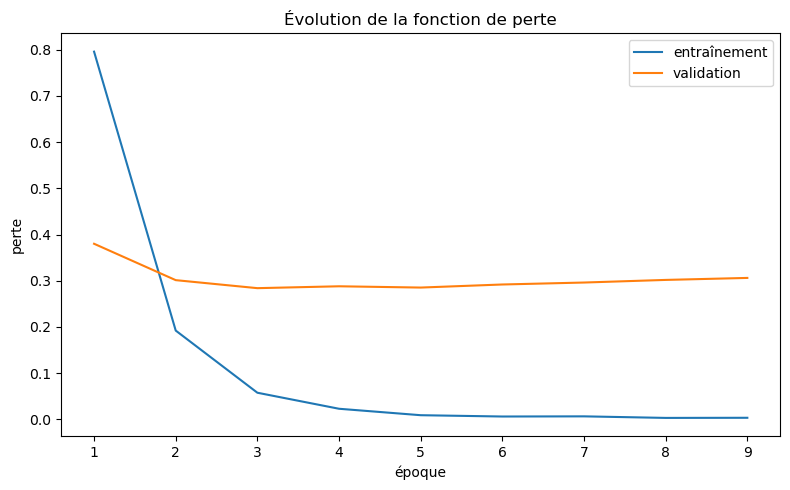

Figure créée : figures/ia/courbe_perte.png


In [13]:
# Courbe de la fonction de perte

plt.figure(figsize=(8, 5))

plt.plot(
    historique.index,
    historique["loss"],
    label="entraînement",
)

plt.plot(
    historique.index,
    historique["val_loss"],
    label="validation",
)

plt.xlabel("époque")
plt.ylabel("perte")
plt.title("Évolution de la fonction de perte")
plt.legend()
plt.tight_layout()

FICHIER_COURBE_PERTE = DOSSIER_FIGURES / "courbe_perte.png"
plt.savefig(
    FICHIER_COURBE_PERTE,
    dpi=160,
)
plt.show()

print("Figure créée :", FICHIER_COURBE_PERTE)


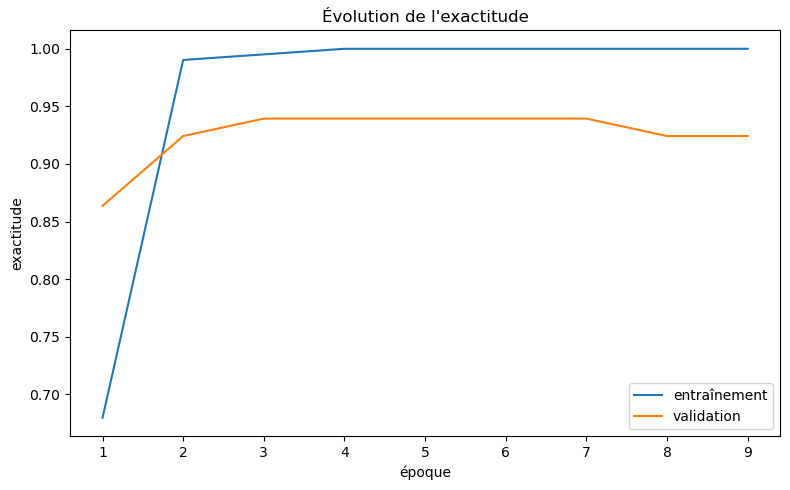

Figure créée : figures/ia/courbe_exactitude.png


In [14]:
# Courbe de l'exactitude

plt.figure(figsize=(8, 5))

plt.plot(
    historique.index,
    historique["accuracy"],
    label="entraînement",
)

plt.plot(
    historique.index,
    historique["val_accuracy"],
    label="validation",
)

plt.xlabel("époque")
plt.ylabel("exactitude")
plt.title("Évolution de l'exactitude")
plt.legend()
plt.tight_layout()

FICHIER_COURBE_ACCURACY = DOSSIER_FIGURES / "courbe_exactitude.png"
plt.savefig(
    FICHIER_COURBE_ACCURACY,
    dpi=160,
)
plt.show()

print("Figure créée :", FICHIER_COURBE_ACCURACY)


<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">XII</span>
&nbsp;—&nbsp;
Enregistrement du modèle et vérification du rechargement
</h2>


La documentation officielle de Keras recommande le format `.keras` pour
enregistrer un modèle complet. Ce format conserve notamment l'architecture et
les poids appris.

La couche `TextVectorization` faisant directement partie du modèle, le fichier
sauvegardé contient également la transformation nécessaire pour convertir un
nouveau passage textuel avant sa classification.

Nous enregistrons en parallèle un fichier JSON contenant la correspondance des
classes et les bulletins utilisés dans chaque partition.



In [15]:
# Sauvegarde du modèle et de ses métadonnées

FICHIER_MODELE = DOSSIER_MODELES / "classifieur_passages_ovsm.keras"
FICHIER_META_MODELE = DOSSIER_MODELES / "classifieur_passages_ovsm.json"

model.save(FICHIER_MODELE)

meta_modele = {
    "classes": CLASSES,
    "classe_vers_id": CLASSE_VERS_ID,
    "max_tokens": MAX_TOKENS,
    "ngrams": 2,
    "representation": "tf_idf",
    "mois_entrainement": MOIS_ENTRAINEMENT,
    "mois_validation": MOIS_VALIDATION,
    "mois_test": MOIS_TEST,
    "seed": SEED,
}

FICHIER_META_MODELE.write_text(
    json.dumps(
        meta_modele,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

# Vérification : le modèle rechargé doit produire la même classe
# sur un même passage.
modele_recharge = keras.models.load_model(
    FICHIER_MODELE
)

if len(X_test):
    proba_avant = model.predict(
        X_test[:1],
        verbose=0,
    )
    proba_apres = modele_recharge.predict(
        X_test[:1],
        verbose=0,
    )

    np.testing.assert_allclose(
        proba_avant,
        proba_apres,
        rtol=1e-5,
        atol=1e-6,
    )

print("Modèle enregistré :", FICHIER_MODELE)
print("Métadonnées        :", FICHIER_META_MODELE)
print("Contrôle de rechargement : OK")


Modèle enregistré : modeles/classifieur_passages_ovsm.keras
Métadonnées        : modeles/classifieur_passages_ovsm.json
Contrôle de rechargement : OK


<h2 style="
    color: #a12424; 
    border-bottom: 2px solid #400b0b;
    padding-bottom: 5px;
    font-size: 1.8em;
">
<span style="
    font-size: 1.15em;
    font-weight: bold;
">XVIII</span>
&nbsp;—&nbsp;
Classification automatique de nouveaux passages
</h2>


L'objectif final est de ne plus avoir à attribuer manuellement l'une des trois
classes à un nouveau passage. La fonction suivante charge le modèle enregistré,
reçoit une chaîne de caractères ou une liste de passages, puis renvoie :

- la classe la plus probable ;
- la probabilité associée ;
- les probabilités des trois classes.

Un seuil de confiance est ajouté. Lorsque la probabilité maximale est inférieure
à ce seuil, la sortie devient `a_verifier`. Le programme ne prétend donc pas
qu'une prédiction incertaine est une décision fiable.

Cette fonction doit être utilisée sur des passages relevant du même domaine que
le corpus d'apprentissage. Le modèle ne comporte pas de quatrième classe
« hors sujet ».



In [16]:
import tensorflow as tf
# Fonction réutilisable de classification

def classer_passages(
    textes,
    seuil=0.60,
    fichier_modele=FICHIER_MODELE,
):
    if isinstance(textes, str):
        textes = [textes]

    textes = [
        str(texte).strip()
        for texte in textes
        if str(texte).strip()
    ]

    if not textes:
        return pd.DataFrame(
            columns=[
                "texte",
                "classe_predite",
                "probabilite_max",
            ]
        )

    modele = keras.models.load_model(
        fichier_modele
    )

    probas = modele.predict(
        # passages sont longs NumPy créé Unicode traduit par Keras 
        # dans un format non reconnu str41408
        # https://stackoverflow.com/questions/78199656/valueerror-invalid-dtype-object-in-tensorflow-model-fit
        # np.asarray(textes),
        tf.constant(textes, dtype=tf.string),
        verbose=0,
    )

    indices = probas.argmax(axis=1)
    pmax = probas.max(axis=1)

    lignes = []

    for texte, indice, confiance, vecteur in zip(
        textes,
        indices,
        pmax,
        probas,
    ):
        classe = ID_VERS_CLASSE[int(indice)]

        if confiance < seuil:
            classe_affichee = "a_verifier"
        else:
            classe_affichee = classe

        ligne = {
            "texte": texte,
            "classe_predite": classe_affichee,
            "meilleure_classe": classe,
            "probabilite_max": float(confiance),
        }

        for i, nom_classe in ID_VERS_CLASSE.items():
            ligne[f"p_{nom_classe}"] = float(vecteur[i])

        lignes.append(ligne)

    return pd.DataFrame(lignes)


# Démonstration sur quelques passages du jeu de test.
# Le test sert ici uniquement à montrer le format de sortie.
demo = classer_passages(
    X_test[:5],
    seuil=0.60,
)

display(demo)


,texte,classe_predite,meilleure_classe,probabilite_max,p_sismicite_volcanique,p_deformation_sol,p_geochimie
0,Septembre Octobre Novembre Typedeséismed’origi...,sismicite_volcanique,sismicite_volcanique,1.000000,1.000000,6.742863e-09,1.022443e-10
1,"Types: Volcanique LP Profond (8), Hybride (8),...",sismicite_volcanique,sismicite_volcanique,1.000000,1.000000,3.516950e-07,5.603821e-09
2,"Hybride (8), Volcano−Tectonique (56), PROC.FWI...",sismicite_volcanique,sismicite_volcanique,0.967234,0.967234,2.790017e-02,4.865716e-03
3,Ces évènements sont qualifiés de profonds s’il...,sismicite_volcanique,sismicite_volcanique,0.966138,0.966138,2.297793e-02,1.088436e-02
4,Les9séismesprofondsdetypelongue-périodeethybri...,sismicite_volcanique,sismicite_volcanique,0.981401,0.981401,1.382198e-02,4.777185e-03


<h3 style="
    color: #4F7F52;
    border-bottom: 1px solid #4F7F52;
    padding-bottom: 3px;
    font-size: 1.25em;
">
<span style="
    font-weight: bold;
    font-style: italic;
">2.</span>
&nbsp;
Fonction d'application à un bulletin présent dans la base SQLite
</h3>


Pour automatiser l'utilisation du classifieur, nous ajoutons une seconde fonction.
Elle récupère le texte propre d'un bulletin dans SQLite, le découpe en passages
sans utiliser leurs étiquettes, puis appelle le modèle.

Le résultat est enregistré dans un fichier CSV. Les passages de faible confiance
restent signalés par `a_verifier`.

Cette fonction permet donc d'appliquer le réseau après son entraînement sans
reconstruire manuellement la chaîne de traitement.



In [17]:
# Application automatique à un bulletin entier

def segmenter_texte_libre(
    texte,
    min_mots=35,
    max_mots=170,
):
    """
    Découpage sans utiliser la classe de la rubrique.
    Les titres manifestes sont retirés afin de ne pas fournir directement
    le nom d'une classe au réseau.
    """
    lignes = []

    for ligne in str(texte).splitlines():
        if identifier_rubrique(ligne) is not None:
            continue

        s = simplifier_chaine(ligne)

        if not s:
            continue
        if s.startswith("institut de physique du globe"):
            continue
        if s.startswith("lieu dit blondel"):
            continue
        if s.startswith("www.ipgp.fr"):
            continue
        if re.match(r"^figure\s+\d+\s*[-–—]", ligne.strip(), flags=re.I):
            continue

        lignes.append(ligne.strip())

    texte_sans_titres = " ".join(lignes)

    return decouper_en_passages(
        texte_sans_titres,
        min_mots=min_mots,
        max_mots=max_mots,
    )


def classer_bulletin(
    mois,
    seuil=0.60,
    fichier_db=FICHIER_DB,
):
    con = sqlite3.connect(fichier_db)

    ligne = con.execute(
        """
        SELECT texte_propre
        FROM bulletin
        WHERE mois = ?
        """,
        (mois,),
    ).fetchone()

    con.close()

    if ligne is None:
        raise ValueError(
            f"Bulletin absent de la base : {mois}"
        )

    nouveaux_passages = segmenter_texte_libre(
        ligne[0]
    )

    predictions = classer_passages(
        nouveaux_passages,
        seuil=seuil,
    )

    predictions.insert(
        0,
        "mois",
        mois,
    )

    sortie = DOSSIER_IA / f"predictions_{mois}.csv"

    predictions.to_csv(
        sortie,
        index=False,
        encoding="utf-8",
    )

    print(
        f"{len(predictions)} passages classés. "
        f"Fichier créé : {sortie}"
    )

    return predictions


# Exemple d'utilisation après entraînement :
resultat_nouveau = classer_bulletin("2025_12", seuil=0.60)
display(resultat_nouveau.head(20))


49 passages classés. Fichier créé : data/ia/predictions_2025_12.csv


,mois,texte,classe_predite,meilleure_classe,probabilite_max,p_sismicite_volcanique,p_deformation_sol,p_geochimie
0,2025_12,Décembre 2025 A) Activité volcanique de la Mon...,sismicite_volcanique,sismicite_volcanique,0.983578,0.983578,1.387468e-02,2.546919e-03
1,2025_12,"Depuis avril 2019, l’activité sismique d’origi...",sismicite_volcanique,sismicite_volcanique,0.998210,0.998210,1.725698e-03,6.414662e-05
2,2025_12,Les zones de végétationdégradéesurleflancsud-o...,sismicite_volcanique,sismicite_volcanique,0.997095,0.997095,2.589147e-03,3.159792e-04
3,2025_12,Cette source pourrait être engendrée par la re...,sismicite_volcanique,sismicite_volcanique,0.999115,0.999115,8.605451e-04,2.423924e-05
4,2025_12,Les déformations de l’édifice restent faibles ...,sismicite_volcanique,sismicite_volcanique,0.861674,0.861674,8.933843e-02,4.898733e-02
5,2025_12,Rappelons que lors des phases de réactivation ...,a_verifier,sismicite_volcanique,0.556527,0.556527,3.195603e-01,1.239124e-01
6,2025_12,Septembre Octobre Novembre Décembre Typedeséis...,sismicite_volcanique,sismicite_volcanique,1.000000,1.000000,6.029111e-09,7.846147e-11
7,2025_12,"Types: Volcanique LP Profond (1), Hybride (3),...",sismicite_volcanique,sismicite_volcanique,0.999999,0.999999,6.481893e-07,1.700267e-08
8,2025_12,"Hybride (3), Volcano−Tectonique (50), PROC.FWI...",sismicite_volcanique,sismicite_volcanique,0.992123,0.992123,7.064554e-03,8.122203e-04
9,2025_12,"Comparativementauxséismesvolcano-tectoniques,l...",sismicite_volcanique,sismicite_volcanique,0.989110,0.989110,9.012918e-03,1.876859e-03
